# Figure 5 — Architecture ablation and gene-count robustness

Run **Restart Kernel and Run All Cells**. Every panel is redrawn from checked numerical tables; no saved manuscript image is used as an input. The cells export new PNG/PDF/SVG files and assemble the complete figure.

This notebook follows the manuscript snapshot dated 2026-10-13. [Plotting source](../reproduction/figure5.py) · [Data provenance](../reproduction/manifest.json) · [Reproduction guide](README.md). The original model implementation and frozen selection remain unchanged. Training seeds measure optimization variability, not biological replication.

In [1]:
from pathlib import Path
import os
import sys

# Works from the repository root or notebooks/; an explicit root is optional.
configured = os.environ.get("SPIKE_CODE_ROOT")
REPO_ROOT = Path(configured).expanduser().resolve() if configured else next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "reproduction/manifest.json").is_file()
)
sys.path.insert(0, str(REPO_ROOT))
%matplotlib inline
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png")
import matplotlib.pyplot as plt
from IPython.display import display
from reproduction.common import audit, read, save, finish, OUTPUT
from reproduction import figure5 as drawing

manifest = audit()
figures = {}


Input audit: PASS (33 numerical tables)
Figure protocol: Released manuscript graph predictions for all seven datasets; matched split-42 State, seeds 41/42/43. Original frozen model selection remains unchanged.


## A. Architecture ablation

Historical Full model, Single decoder, Standard GAT and No edge features. Each point is a dataset mean over three seeds. Boxes show median/IQR and 1.5-IQR whiskers; black lines show means. Brackets use exact paired Wilcoxon tests on seven dataset pairs with Holm correction within each metric.

Numerical input: [`fig4a_architecture_ablation_per_seed.csv`](../reproduction/tables/fig4a_architecture_ablation_per_seed.csv).

Source table: fig4a_architecture_ablation_per_seed.csv (84, 9)


,dataset,variant,seed,Pearson,RMSE,source_table,n_features,split_seed,metric_space
0,brain_sleep1,spike,41,0.997337,0.124507,fig4a_metrics_per_seed.csv,5000,42,fixed5000_shared_feature_mean_vectors
1,brain_sleep1,spike,42,0.997650,0.108818,fig4a_metrics_per_seed.csv,5000,42,fixed5000_shared_feature_mean_vectors
2,brain_sleep1,spike,43,0.997345,0.117973,fig4a_metrics_per_seed.csv,5000,42,fixed5000_shared_feature_mean_vectors
3,brain_sleep1,single_decoder,41,0.989029,0.230129,fig4a_metrics_per_seed.csv,5000,42,fixed5000_shared_feature_mean_vectors
4,brain_sleep1,single_decoder,42,0.988895,0.234361,fig4a_metrics_per_seed.csv,5000,42,fixed5000_shared_feature_mean_vectors


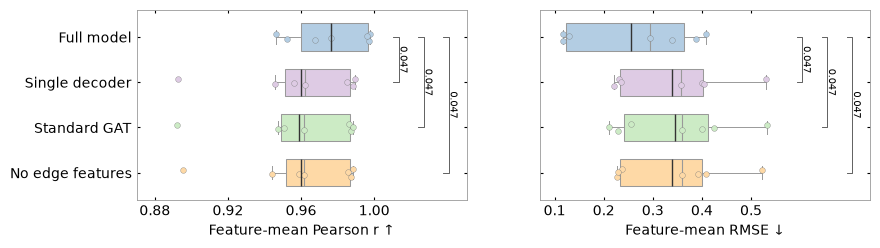

In [2]:
data_a = read('fig4a_architecture_ablation_per_seed.csv')
print("Source table:", 'fig4a_architecture_ablation_per_seed.csv', data_a.shape)
display(data_a.head(5))
figures['a'] = drawing.panel_a()
save(figures['a'], 5, 'a')
display(figures['a'])
plt.close(figures['a'])

## B. Distribution-pair RMSE

Violin plots summarize seven dataset means for each historical variant. Independent source and target samples are used; they are not biologically paired cells.

Numerical input: [`fig4b_architecture_means.csv`](../reproduction/tables/fig4b_architecture_means.csv).

Source table: fig4b_architecture_means.csv (28, 4)


,dataset,variant,distribution_pair_rmse,n_pairs
0,PSAPP,no_edge,0.610789,500
1,PSAPP,single_decoder,0.608242,500
2,PSAPP,spike,0.599420,500
3,PSAPP,standard_gat,0.605920,500
4,SHH,no_edge,0.791243,500


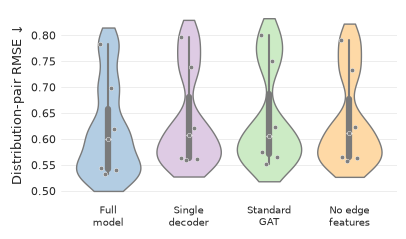

In [3]:
data_b = read('fig4b_architecture_means.csv')
print("Source table:", 'fig4b_architecture_means.csv', data_b.shape)
display(data_b.head(5))
figures['b'] = drawing.panel_b()
save(figures['b'], 5, 'b')
display(figures['b'])
plt.close(figures['b'])

## C. SHH spatial ablation

Map1b predictions at the same 880 SHH source spots. Four historical variants share physical coordinates and pooled 2nd/98th-percentile color limits; colorbar triangles mark clipped tails.

Numerical input: [`original_spatial_values.csv`](../reproduction/tables/original_spatial_values.csv).

Source table: original_spatial_values.csv (3520, 7)


,spot_id,dataset,gene,method,x,y,expression
0,AAACCCGAACGAAATC-1-c,SHH,Map1b,spike,45.0,115.0,4.226077
1,AAACGAAGATGGAGTA-1-c,SHH,Map1b,spike,58.0,4.0,4.262406
2,AAACGGGCGTACGGGT-1-c,SHH,Map1b,spike,65.0,91.0,4.255878
3,AAACTTGCAAACGTAT-1-c,SHH,Map1b,spike,45.0,19.0,3.898813
4,AAAGACCCAAGTCGCG-1-c,SHH,Map1b,spike,10.0,48.0,4.069581


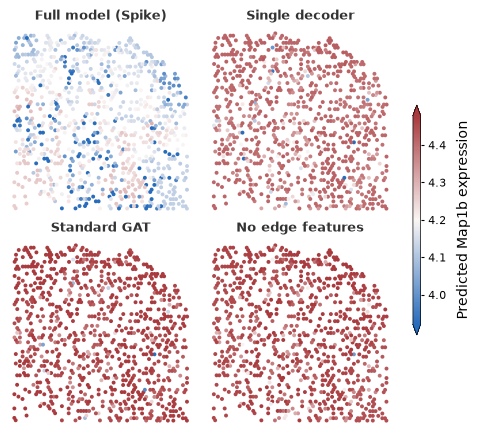

In [4]:
data_c = read('original_spatial_values.csv')
print("Source table:", 'original_spatial_values.csv', data_c.shape)
display(data_c.head(5))
figures['c'] = drawing.panel_c()
save(figures['c'], 5, 'c')
display(figures['c'])
plt.close(figures['c'])

## D. LR coexpression agreement

Ten LR pairs selected by observed target covariance. Bars show mean 1 − |r_pred − r_target|/2 over three seeds. Stars mark historical Full model ties or maxima, not significance. The axis begins at 0.50.

Numerical input: [`fig4e_lr_summary.csv`](../reproduction/tables/fig4e_lr_summary.csv).

Source table: fig4e_lr_summary.csv (40, 7)


,selection_rank,lr_pair,variant,agreement_mean,agreement_sd,n_seeds,target_corr
0,1,Tgfb3–Acvr1,spike,0.844188,0.103290,3,0.165457
1,2,Col3a1–Ddr2,spike,0.745519,0.191211,3,0.147021
2,3,Ntf3–Ntrk3,spike,0.711857,0.108145,3,0.106041
3,4,Tgfb3–Tgfbr1,spike,0.893097,0.096984,3,0.069541
4,5,Adcyap1–Ramp3,spike,0.849754,0.115067,3,0.110823


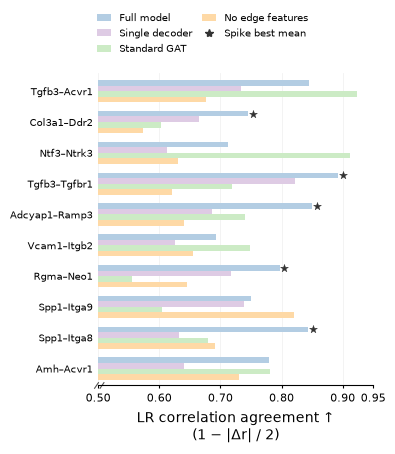

In [5]:
data_d = read('fig4e_lr_summary.csv')
print("Source table:", 'fig4e_lr_summary.csv', data_d.shape)
display(data_d.head(5))
figures['d'] = drawing.panel_d()
save(figures['d'], 5, 'd')
display(figures['d'])
plt.close(figures['d'])

## E. Gene-count robustness

Current manuscript graph Spike and four comparators at 1k, 2k, 5k and 10k genes. Curves average seeds within each dataset, then weight seven datasets equally. Matched State results replace the earlier unmatched overlay. Historical Full model in A–D differs from the conditional residual model in E.

Numerical input: [`gene_count_per_seed.csv`](../reproduction/tables/gene_count_per_seed.csv).

Source table: gene_count_per_seed.csv (420, 6)


,dataset,gene_length,method,seed,Pearson,RMSE
0,brain_sleep1,1000,scGen,41,0.947644,0.346226
1,brain_sleep1,1000,scGen,42,0.877035,0.663671
2,brain_sleep1,1000,scGen,43,0.992438,0.375539
3,brain_sleep1,1000,scGPT,41,0.943057,0.762912
4,brain_sleep1,1000,scGPT,42,0.948592,0.772502


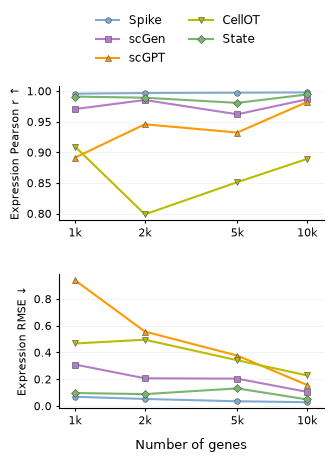

In [6]:
data_e = read('gene_count_per_seed.csv')
print("Source table:", 'gene_count_per_seed.csv', data_e.shape)
display(data_e.head(5))
figures['e'] = drawing.panel_e()
save(figures['e'], 5, 'e')
display(figures['e'])
plt.close(figures['e'])

## Complete figure and output verification

The composite uses only the figures generated above, assembled in memory. It writes `complete.png`, `complete.pdf`, `complete.svg` and a validation record.

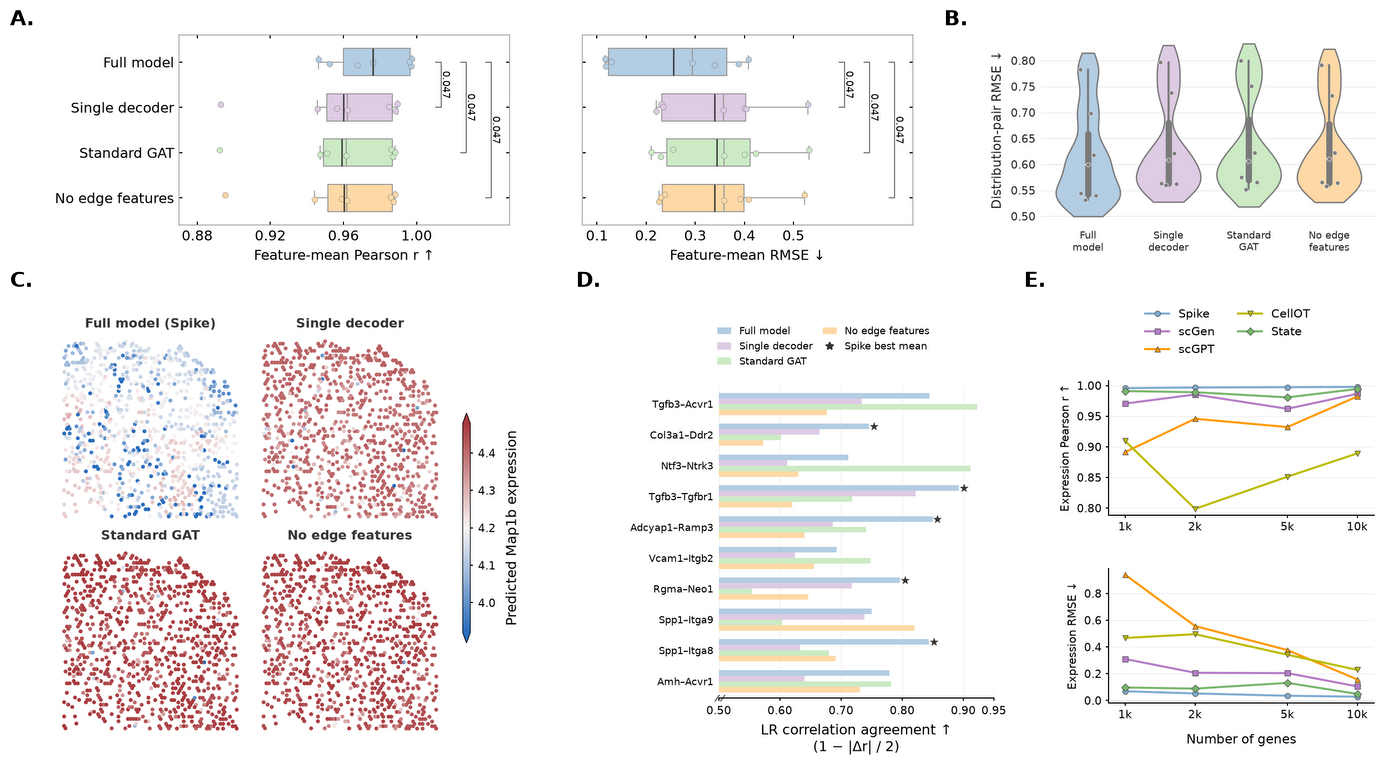

Figure 5: PASS — 5 panels redrawn from numerical tables
Outputs: /Users/jasmine/Documents/GitHub/spike/outputs/reproduction/figure5


In [7]:
complete = drawing.complete(figures)
save(complete, 5, "complete")
display(complete)
plt.close(complete)
report = finish(5, drawing.PANELS)